In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/creditcard.csv")

print(df.shape)
print(df.head())
print(df.info())
print(df.isnull().sum().sum())   # missing values

(284807, 31)
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V

In [3]:
print(df['Class'].value_counts())
print(df['Class'].value_counts(normalize=True) * 100)

Class
0    284315
1       492
Name: count, dtype: int64
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


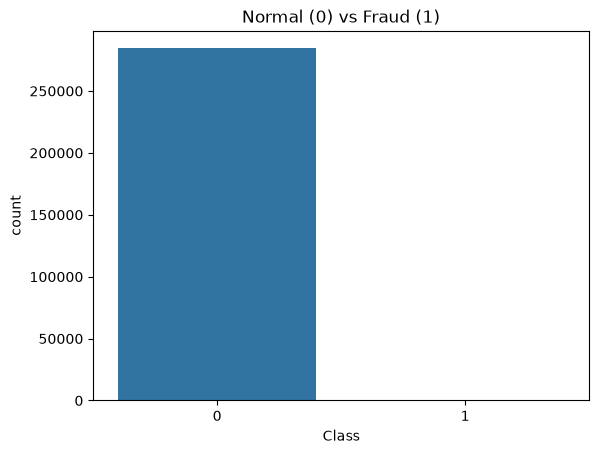

In [4]:
sns.countplot(x='Class', data=df)
plt.title("Normal (0) vs Fraud (1)")
plt.show()

In [5]:
print(df.groupby('Class')['Amount'].describe())

          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87


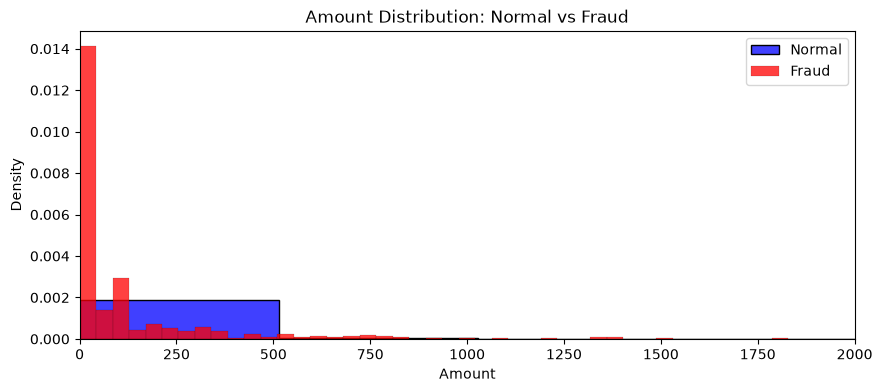

In [6]:
plt.figure(figsize=(10,4))
sns.histplot(df[df.Class==0]['Amount'], bins=50, color='blue', label='Normal', stat='density')
sns.histplot(df[df.Class==1]['Amount'], bins=50, color='red', label='Fraud', stat='density')
plt.legend()
plt.xlim(0, 2000)
plt.title("Amount Distribution: Normal vs Fraud")
plt.show()

In [7]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 1081


In [8]:
print(df[df.duplicated()]['Class'].value_counts())

Class
0    1062
1      19
Name: count, dtype: int64


In [9]:
df = df.drop_duplicates()
print(df.shape)
print(df['Class'].value_counts())

(283726, 31)
Class
0    283253
1       473
Name: count, dtype: int64


In [10]:
from sklearn.preprocessing import RobustScaler
import joblib

scaler_amount = RobustScaler()
scaler_time = RobustScaler()

df['Amount'] = scaler_amount.fit_transform(df[['Amount']])
df['Time'] = scaler_time.fit_transform(df[['Time']])

df[['Amount', 'Time']].describe()

,Amount,Time
count,283726.000000,283726.000000
mean,0.924387,0.118912
std,3.482123,0.557988
min,-0.305938,-0.995290
25%,-0.228063,-0.358286
50%,0.000000,0.000000
75%,0.771937,0.641714
max,356.962314,1.035329


In [11]:
from sklearn.model_selection import train_test_split

X = df.drop('Class', axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Train fraud %:", y_train.mean()*100)
print("Test fraud %:", y_test.mean()*100)

Train shape: (198608, 30)
Test shape: (85118, 30)
Train fraud %: 0.16665995327479255
Test fraud %: 0.1668272280833666


In [12]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score
import numpy as np

model = IsolationForest(n_estimators=100, contamination=0.00167, random_state=42, n_jobs=-1)
model.fit(X_train)

,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",0.00167
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",100
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


In [13]:
pred = model.predict(X_test)
pred = np.where(pred == -1, 1, 0)  # convert -1(anomaly)->1(fraud), 1(normal)->0

print(classification_report(y_test, pred))
print(confusion_matrix(y_test, pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     84976
           1       0.26      0.27      0.26       142

    accuracy                           1.00     85118
   macro avg       0.63      0.63      0.63     85118
weighted avg       1.00      1.00      1.00     85118

[[84865   111]
 [  104    38]]


In [14]:
scores = -model.decision_function(X_test)  # higher score = more anomalous
pr_auc = average_precision_score(y_test, scores)
print("PR-AUC:", pr_auc)

PR-AUC: 0.13346867719857633


In [15]:
print(classification_report(y_test, pred))
print(confusion_matrix(y_test, pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     84976
           1       0.26      0.27      0.26       142

    accuracy                           1.00     85118
   macro avg       0.63      0.63      0.63     85118
weighted avg       1.00      1.00      1.00     85118

[[84865   111]
 [  104    38]]


In [16]:
model2 = IsolationForest(n_estimators=200, contamination=0.005, max_samples=0.8, random_state=42, n_jobs=-1)
model2.fit(X_train)

pred2 = model2.predict(X_test)
pred2 = np.where(pred2 == -1, 1, 0)

print(classification_report(y_test, pred2))
print(confusion_matrix(y_test, pred2))

scores2 = -model2.decision_function(X_test)
print("PR-AUC:", average_precision_score(y_test, scores2))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     84976
           1       0.18      0.57      0.27       142

    accuracy                           0.99     85118
   macro avg       0.59      0.78      0.64     85118
weighted avg       1.00      0.99      1.00     85118

[[84606   370]
 [   61    81]]
PR-AUC: 0.19370341497965327


In [17]:
model3 = IsolationForest(n_estimators=300, random_state=42, n_jobs=-1)
model3.fit(X_train)

scores3 = -model3.decision_function(X_test)
print("PR-AUC (model3):", average_precision_score(y_test, scores3))

PR-AUC (model3): 0.1020258330712123


In [18]:
from sklearn.neighbors import LocalOutlierFactor

lof = LocalOutlierFactor(n_neighbors=20, contamination=0.00167, novelty=True, n_jobs=-1)
lof.fit(X_train)

pred_lof = lof.predict(X_test)
pred_lof = np.where(pred_lof == -1, 1, 0)

print(classification_report(y_test, pred_lof))
print(confusion_matrix(y_test, pred_lof))

scores_lof = -lof.decision_function(X_test)
print("PR-AUC (LOF):", average_precision_score(y_test, scores_lof))

c:\Users\astha\fraud-detection\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


              precision    recall  f1-score   support

           0       1.00      1.00      1.00     84976
           1       0.00      0.00      0.00       142

    accuracy                           1.00     85118
   macro avg       0.50      0.50      0.50     85118
weighted avg       1.00      1.00      1.00     85118

[[84821   155]
 [  142     0]]


c:\Users\astha\fraud-detection\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


PR-AUC (LOF): 0.002365876678581953


In [19]:
model4 = IsolationForest(
    n_estimators=200,
    contamination=0.01,
    max_samples=0.8,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)
model4.fit(X_train)

pred4 = model4.predict(X_test)
pred4 = np.where(pred4 == -1, 1, 0)

print(classification_report(y_test, pred4))
print(confusion_matrix(y_test, pred4))

scores4 = -model4.decision_function(X_test)
print("PR-AUC (model4):", average_precision_score(y_test, scores4))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99     84976
           1       0.11      0.67      0.18       142

    accuracy                           0.99     85118
   macro avg       0.55      0.83      0.59     85118
weighted avg       1.00      0.99      0.99     85118

[[84174   802]
 [   47    95]]
PR-AUC (model4): 0.17710496273024384


In [20]:
model5 = IsolationForest(
    n_estimators=150,
    contamination=0.003,
    max_samples=256,
    random_state=42,
    n_jobs=-1
)
model5.fit(X_train)

scores5 = -model5.decision_function(X_test)
print("PR-AUC (model5):", average_precision_score(y_test, scores5))

PR-AUC (model5): 0.11291119565079506


In [21]:
# Autoencoder ko sirf normal transactions pe train karenge
X_train_normal = X_train[y_train == 0]

print("Normal training data shape:", X_train_normal.shape)

Normal training data shape: (198277, 30)


In [22]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.callbacks import EarlyStopping

input_dim = X_train_normal.shape[1]  # 30 features

# Encoder-Decoder architecture
input_layer = Input(shape=(input_dim,))
encoded = Dense(20, activation='relu')(input_layer)
encoded = Dense(14, activation='relu')(encoded)
encoded = Dense(7, activation='relu')(encoded)
decoded = Dense(14, activation='relu')(encoded)
decoded = Dense(20, activation='relu')(decoded)
decoded = Dense(input_dim, activation='linear')(decoded)

autoencoder = Model(inputs=input_layer, outputs=decoded)
autoencoder.compile(optimizer='adam', loss='mse')

autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 30)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 20)             │           620 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 14)             │           294 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │           105 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 14)             │           112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 20)             │           300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 30)             │           630 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,061 (8.05 KB)

 Trainable params: 2,061 (8.05 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
early_stop = EarlyStopping(monitor='loss', patience=5, restore_best_weights=True)

history = autoencoder.fit(
    X_train_normal, X_train_normal,   # input aur output dono same (normal data)
    epochs=50,
    batch_size=256,
    shuffle=True,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
698/698 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - loss: 0.7287 - val_loss: 0.4570
Epoch 2/50
698/698 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.4164 - val_loss: 0.3741
Epoch 3/50
698/698 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.3652 - val_loss: 0.3467
Epoch 4/50
698/698 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.3371 - val_loss: 0.3146
Epoch 5/50
698/698 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.3172 - val_loss: 0.3024
Epoch 6/50
698/698 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.3042 - val_loss: 0.2906
Epoch 7/50
698/698 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.2946 - val_loss: 0.2859
Epoch 8/50
698/698 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.2879 - val_loss: 0.2808
Epoch 9/50
698/698 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.2826 - val_loss: 0.2767
Epoch 10/50
698/698 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.2792 - val_loss: 0.2734
Epoch 11/50
698/698 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.2764 - val_loss: 0.2746
Epoch 12/50
698/698 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step

In [24]:
import numpy as np

# Test data ko reconstruct karo
X_test_pred = autoencoder.predict(X_test)

# Reconstruction error nikaalo (MSE per row)
mse = np.mean(np.power(X_test - X_test_pred, 2), axis=1)

print("Reconstruction error - Normal transactions avg:", mse[y_test==0].mean())
print("Reconstruction error - Fraud transactions avg:", mse[y_test==1].mean())

2660/2660 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step
Reconstruction error - Normal transactions avg: 0.23248869721894
Reconstruction error - Fraud transactions avg: 14.86166363614652


In [25]:
from sklearn.metrics import average_precision_score, classification_report, confusion_matrix

pr_auc_ae = average_precision_score(y_test, mse)
print("PR-AUC (Autoencoder):", pr_auc_ae)

PR-AUC (Autoencoder): 0.518185904745686


In [26]:
# Threshold: 95th percentile of normal transaction errors (ya kuch aur try kar sakte hain)
threshold = np.percentile(mse[y_test==0], 99)
print("Threshold:", threshold)

pred_ae = np.where(mse > threshold, 1, 0)

print(classification_report(y_test, pred_ae))
print(confusion_matrix(y_test, pred_ae))

Threshold: 0.9914774860552404
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     84976
           1       0.12      0.80      0.20       142

    accuracy                           0.99     85118
   macro avg       0.56      0.89      0.60     85118
weighted avg       1.00      0.99      0.99     85118

[[84126   850]
 [   29   113]]


In [27]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("Before SMOTE:", y_train.value_counts())
print("After SMOTE:", y_train_smote.value_counts())

Before SMOTE: Class
0    198277
1       331
Name: count, dtype: int64
After SMOTE: Class
0    198277
1    198277
Name: count, dtype: int64


In [28]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train_smote, y_train_smote)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [29]:
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score

pred_rf = rf.predict(X_test)

print(classification_report(y_test, pred_rf))
print(confusion_matrix(y_test, pred_rf))

# PR-AUC ke liye probability chahiye, prediction nahi
proba_rf = rf.predict_proba(X_test)[:, 1]  # fraud class ki probability
pr_auc_rf = average_precision_score(y_test, proba_rf)
print("PR-AUC (Random Forest + SMOTE):", pr_auc_rf)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     84976
           1       0.91      0.75      0.82       142

    accuracy                           1.00     85118
   macro avg       0.95      0.87      0.91     85118
weighted avg       1.00      1.00      1.00     85118

[[84965    11]
 [   36   106]]
PR-AUC (Random Forest + SMOTE): 0.8113245899090078


                      Model                    Type  Recall  Precision  PR_AUC
0          Isolation Forest       Anomaly Detection    0.27       0.26   0.133
1  Isolation Forest (Tuned)       Anomaly Detection    0.57       0.18   0.194
2                       LOF       Anomaly Detection    0.00       0.00   0.002
3               Autoencoder  Anomaly Detection (DL)    0.80       0.12   0.518
4     Random Forest + SMOTE              Supervised    0.75       0.91   0.811


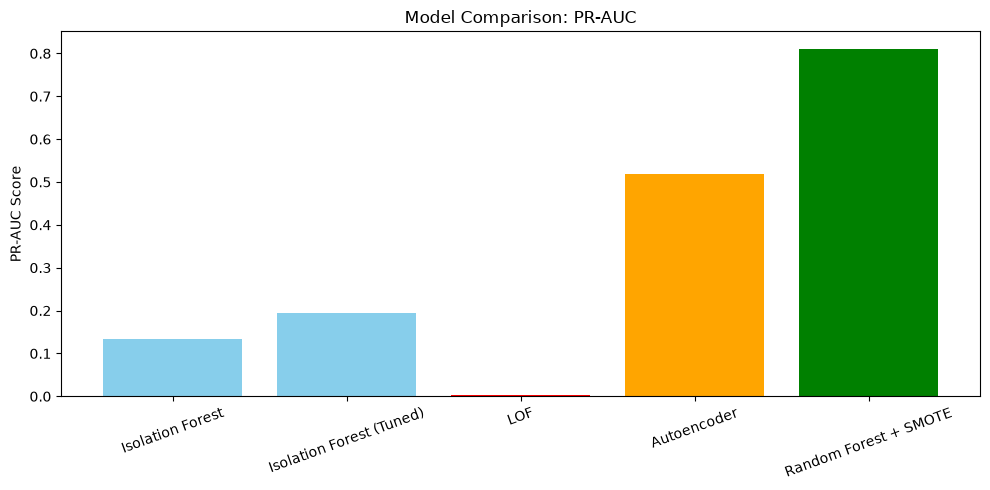

In [30]:
import pandas as pd
import matplotlib.pyplot as plt

results = pd.DataFrame({
    'Model': ['Isolation Forest', 'Isolation Forest (Tuned)', 'LOF', 'Autoencoder', 'Random Forest + SMOTE'],
    'Type': ['Anomaly Detection', 'Anomaly Detection', 'Anomaly Detection', 'Anomaly Detection (DL)', 'Supervised'],
    'Recall': [0.27, 0.57, 0.00, 0.80, 0.75],
    'Precision': [0.26, 0.18, 0.00, 0.12, 0.91],
    'PR_AUC': [0.133, 0.194, 0.002, 0.518, 0.811]
})

print(results)

# Bar chart
plt.figure(figsize=(10,5))
plt.bar(results['Model'], results['PR_AUC'], color=['skyblue','skyblue','red','orange','green'])
plt.ylabel('PR-AUC Score')
plt.title('Model Comparison: PR-AUC')
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig('../models/comparison_chart.png')  # report ke liye save
plt.show()

In [31]:
import joblib

# Best anomaly detection model
joblib.dump(model2, '../models/isolation_forest_final.pkl')

# Best overall model
joblib.dump(rf, '../models/random_forest_final.pkl')

# Autoencoder (deep learning model, alag tarike se save hota hai)
autoencoder.save('../models/autoencoder_final.keras')

# Autoencoder ka threshold bhi save karo (prediction ke time chahiye hoga)
import json
with open('../models/autoencoder_threshold.json', 'w') as f:
    json.dump({'threshold': float(threshold)}, f)

print("All models saved successfully!")

All models saved successfully!


In [ ]:
import joblib

joblib.dump(scaler_amount, '../models/scaler_amount.pkl')
joblib.dump(scaler_time, '../models/scaler_time.pkl')

print("Scalers saved!")

Scalers saved!


: 